# 08 F1 dose–response curves and the query-side mirror

This notebook measures how the F1 partial upgrade (`PartialUpgrade`, `src/silent_rag/inject/f1_partial_upgrade.py`) changes retrieval quality and detector statistics as a function of severity (dose), for four replacement models whose difference from the baseline model is measured (§1–2). It also measures the mirror direction (queries on the replacement model, documents on the baseline model) as a separate analysis (§5).

It uses only existing repository code: `silent_rag.run` for the benchmark conditions, `PartialUpgrade`, `Retriever.search`, `per_query_ndcg`, `bootstrap_ci`, the registered detectors, and `compute_auroc` / `bootstrap_auroc_ci`. It uses **NFCorpus only**: the test split for evaluation and the validation split as the detector reference set in §4–5. The held-out datasets are not used.

| § | Content |
|---|---|
| 0 | Setup, definitions, machine record, clean baseline, figure style |
| 1 | Replacement-model check and selection |
| 1b | Reproduction check against notebook 07 |
| 1c | Benchmark run: configuration and command (runs as a separate process) |
| 2 | Difference between each replacement model and the baseline model |
| 3 | F1 dose–response: nDCG@10 decrease vs severity |
| 4 | F1 dose–response: detector statistics vs severity |
| 5 | Query-side mirror (analysis, not a benchmark condition) and the per-query table |
| 6 | AUROC per detector, pooled and per severity |
| 7 | Share of windows labelled harmful at three thresholds |
| 8 | Median computation time per detector check |

§2–5 do not depend on the benchmark run; §6–8 need `results/analysis_f1.parquet` from §1c.

**Run time.** §1 downloads up to four models and embeds the corpus once per model (about 1–3 min each, cached in `cache/embeddings`). §1b takes about 2 min. The benchmark run started from §1c has 41 conditions × 20 windows × 10 seeds = 8,200 windows and takes about 5–8 hours on a laptop CPU, mostly in `re_embed`. §4 and §5 take about 15–25 min each.

## 0. Setup and definitions

- **Severity (dose):** the fraction affected, in (0, 1]. For F1, the fraction of document vectors replaced by the replacement model’s vectors; for the mirror (§5), the fraction of test queries embedded with the replacement model.
- **nDCG@10 decrease:** clean baseline nDCG@10 minus nDCG@10 under the condition, per query (a paired difference). Positive values mean lower retrieval quality.
- **Harmful (window label):** a 100-query window is labelled harmful when the one-sided paired bootstrap test of “no decrease” gives p < α = 0.05 **and** the mean nDCG@10 decrease in the window is ≥ `min_drop`. The runner uses `min_drop` = 0; §7 recomputes the label at `min_drop` = 0, 0.02 and 0.06.
- **Reference set:** the queries a detector is fitted on. In the benchmark run (§1c, §6) it is a 100-query window drawn by the runner; in §4–5 it is the 324 NFCorpus validation queries.
- **Test set:** the 323 NFCorpus test queries.

In [6]:
import os
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')  # macOS: avoids an OpenMP conflict between faiss and torch
os.environ.setdefault('OMP_NUM_THREADS', '1')

import copy
import dataclasses
import itertools
import json
import platform
import re
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

# run from the repo root, so configs/, cache/ and results/ resolve as they do for the runner
ROOT = Path.cwd() if (Path.cwd() / 'configs').exists() else Path.cwd().parent
os.chdir(ROOT)

from silent_rag import data
from silent_rag import run as R
from silent_rag.detect.base import REGISTRY as DETECTORS
from silent_rag.eval.detector_scoring import bootstrap_auroc_ci, compute_auroc
from silent_rag.eval.ground_truth import bootstrap_ci, per_query_ndcg
from silent_rag.inject.f1_partial_upgrade import PartialUpgrade
from silent_rag.pipeline import Retriever

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200)
R.load_plugins()

DEV = yaml.safe_load(open('configs/dev.yaml'))
BASE_MODEL, RETRIEVER_KW = DEV['model'], DEV['retriever']
assert RETRIEVER_KW['max_seq_length'] == 256
K = 10
ALPHA = 0.05
SEVERITIES = [round(0.1 * i, 1) for i in range(1, 11)]
SEEDS = list(range(10))
DETECTOR_NAMES = ['re_embed', 'ks_top1', 'ks_mean10', 'ks_gap', 'psi_top1']
# 0.06: smallest mean nDCG@10 decrease detected in 80% of 100-query windows at alpha = 0.05
# (README, window-size analysis, experiments/baseline/window_size.py)
MIN_DROPS = [0.0, 0.02, 0.06]
FIG_DIR = Path('results/figures/analysis_f1')
RUNNER_PATH = Path('results/analysis_f1.parquet')
QUERIES_PATH = Path('results/analysis_f1_queries.parquet')
CFG_PATH = Path('/tmp/analysis_f1.yaml')
SCRIPT_PATH = Path('/tmp/analysis_f1_run.sh')
LOAD_LOG = Path('/tmp/analysis_f1_load.log')
print(f'baseline model {BASE_MODEL}, retriever settings {RETRIEVER_KW}')

baseline model sentence-transformers/multi-qa-MiniLM-L6-cos-v1, retriever settings {'revision': 'b207367332321f8e44f96e224ef15bc607f4dbf0', 'max_seq_length': 256}


### Machine record

The hardware and library versions of this machine. The benchmark run (§1c) runs on the same machine as a separate process; its wrapper script samples the CPU load and the processes with the highest CPU use once a minute, and §8 reports from that log whether the run overlapped other CPU-intensive processes.

In [7]:
def cpu_name():
    try:
        return subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True, text=True).stdout.strip()
    except OSError:
        return platform.processor()


def machine_record():
    import faiss, sentence_transformers, torch
    return {
        'platform': platform.platform(), 'cpu': cpu_name(), 'cpu_count': os.cpu_count(),
        'python': sys.version.split()[0], 'torch': torch.__version__,
        'sentence_transformers': sentence_transformers.__version__, 'faiss': faiss.__version__,
        'OMP_NUM_THREADS': os.environ.get('OMP_NUM_THREADS'),
    }


MACHINE = machine_record()
print(json.dumps(MACHINE, indent=1))

{
 "platform": "macOS-26.5-arm64-arm-64bit-Mach-O",
 "cpu": "Apple M5 Pro",
 "cpu_count": 15,
 "python": "3.14.6",
 "torch": "2.15.0",
 "sentence_transformers": "6.2.0",
 "faiss": "1.15.1",
 "OMP_NUM_THREADS": "1"
}


### Data and clean baseline

The corpus is embedded once with the baseline model (cached). The validation split has the same corpus and a disjoint set of queries; it is used only as the detector reference set in §4–5.

In [8]:
ds = data.load('nfcorpus')
ds_ref = data.load('nfcorpus', split='validation')
assert not set(ds.queries) & set(ds_ref.queries), 'test and validation queries overlap'

retriever = Retriever(BASE_MODEL, **RETRIEVER_KW)
state = R.read_only(retriever.embed_corpus(ds))
ref_state = R.read_only(retriever.embed_corpus(ds_ref))
assert ref_state.doc_ids == state.doc_ids
RUN_CFG_INJ = R.injector_run_cfg(retriever)

clean_ids, clean_scores, clean_q = retriever.search(state, k=K, query_embeddings=state.query_embeddings)
clean_ndcg = per_query_ndcg(clean_ids, state.query_ids, ds.qrels, K)
m, lo, hi = bootstrap_ci(clean_ndcg)
print(f'clean baseline nDCG@10 = {m:.3f} (95% bootstrap CI {lo:.3f}–{hi:.3f}); test set {len(clean_ndcg)} queries, '
      f'{len(state.doc_ids)} documents; reference set {len(ref_state.query_ids)} validation queries')
assert round(m, 3) == 0.292, f'clean baseline nDCG@10 is {m:.4f}, expected 0.292 (README, 256 tokens)'
REL = {q: [d for d, r in ds.qrels[q].items() if r > 0] for q in state.query_ids}

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 20343.44it/s]


clean baseline nDCG@10 = 0.292 (95% bootstrap CI 0.259–0.325); test set 323 queries, 3633 documents; reference set 324 validation queries


### Figure style

Every figure is 12 × 6.75 in, saved at 200 dpi as PNG and SVG to `results/figures/analysis_f1/`. Each replacement model keeps one colour (Okabe–Ito, colour-blind safe) in every figure, ordered from the highest to the lowest mean cosine with the baseline vectors (§1). The clean baseline is a grey dashed line. Lines are labelled at their right end.

In [9]:
plt.rcParams.update({
    'figure.figsize': (12, 6.75), 'figure.dpi': 100, 'savefig.dpi': 200, 'svg.fonttype': 'none',
    'axes.titlesize': 24, 'axes.labelsize': 20, 'xtick.labelsize': 16, 'ytick.labelsize': 16, 'legend.fontsize': 16,
    'lines.linewidth': 3, 'lines.markersize': 8,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e5e5e5',
    'axes.axisbelow': True, 'axes.titlelocation': 'left',
})
OKABE_ITO = ['#0072B2', '#009E73', '#E69F00', '#D55E00']  # assigned in §1, highest mean cosine first
BASELINE_GREY = '#7F7F7F'


def new_figure(ncols=1, **kw):
    return plt.subplots(1, ncols, figsize=(12, 6.75), layout='constrained', **kw)


def baseline_line(ax, y, text='clean baseline'):
    ax.axhline(y, color=BASELINE_GREY, ls='--', lw=2, zorder=1)
    ax.text(ax.get_xlim()[0], y, f' {text}', color=BASELINE_GREY, fontsize=16, va='bottom')


def label_ends(ax, x, ends, min_gap=0.06):
    # ends: (y, text, colour); labels are spread vertically by at least min_gap of the y-range so they do not overlap
    lo, hi = ax.get_ylim()
    gap, placed = (hi - lo) * min_gap, []
    for y, text, colour in sorted(ends):
        y = max(y, placed[-1] + gap) if placed else y
        placed.append(y)
        ax.text(x, y, f' {text}', color=colour, fontsize=16, va='center', clip_on=False)


def save(fig, name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    for ext in ('png', 'svg'):
        fig.savefig(FIG_DIR / f'{name}.{ext}')
    plt.show()

## 1. Replacement models: check and selection

Two replacement models are fixed by notebook 07 and `configs/dev.yaml`: `all-MiniLM-L6-v2` (`1110a24…`) and `bge-small-en-v1.5` (`5c38ec7…`). Two more are chosen from four candidates.

Each candidate is checked from its saved Hub files at a pinned commit: 384-dimensional output (`1_Pooling/config.json`, no Dense module), a `Normalize` module in `modules.json`, and no query or document prefix (no non-empty `prompts` in `config_sentence_transformers.json`, and no `query: `, `passage: ` or “Represent this sentence” instruction in the model card). It must then pass `PartialUpgrade.check_config` and `PartialUpgrade.attach`, which rejects a dimension mismatch. A candidate that fails any check is listed with the reason and not used.

**Difference measure.** The mean cosine between each document’s baseline vector and its replacement-model vector, over all 3,633 documents (the formula in `site/scripts/make_data.py:85`). Both vectors have unit length, so this is the mean dot product.

**Selection rule.** Among the candidates that pass, the chosen two are the pair that minimises the largest gap between neighbouring mean cosines of the four models.

In [10]:
from huggingface_hub import hf_hub_download, model_info

FIXED = {
    'F1_partial_upgrade_minilm': DEV['failures']['F1_partial_upgrade_minilm'],
    'F1_partial_upgrade_bge': DEV['failures']['F1_partial_upgrade_bge'],
}
CANDIDATES = ['sentence-transformers/all-MiniLM-L12-v2', 'sentence-transformers/paraphrase-MiniLM-L6-v2',
              'sentence-transformers/msmarco-MiniLM-L-6-v3', 'thenlper/gte-small']
BGE_INSTRUCTION = 'Represent this sentence for searching relevant passages: '  # bge-small model card, notebook 01:83
PREFIX_PATTERNS = 'query: |passage: |Represent this sentence'


def hub_file(repo, revision, name):
    try:
        return Path(hf_hub_download(repo, name, revision=revision))
    except Exception:
        return None


def inspect_model(repo, revision=None):
    revision = revision or model_info(repo).sha
    info = {'model': repo, 'revision': revision}
    modules_file = hub_file(repo, revision, 'modules.json')
    if modules_file is None:
        return {**info, 'modules': None, 'dim': None, 'normalize': False, 'dense': False, 'prompts': {}, 'card_prefixes': []}
    modules = json.loads(modules_file.read_text())
    types = [mod['type'].rsplit('.', 1)[-1] for mod in modules]
    pool_path = next(mod['path'] for mod in modules if mod['type'].endswith('Pooling'))
    dim = json.loads(hub_file(repo, revision, f'{pool_path}/config.json').read_text())['word_embedding_dimension']
    st_cfg = hub_file(repo, revision, 'config_sentence_transformers.json')
    prompts = json.loads(st_cfg.read_text()).get('prompts') or {} if st_cfg else {}
    card = hub_file(repo, revision, 'README.md')
    card_prefixes = sorted(set(re.findall(PREFIX_PATTERNS, card.read_text(errors='ignore')))) if card else []
    return {**info, 'modules': '+'.join(types), 'dim': dim, 'normalize': 'Normalize' in types,
            'dense': 'Dense' in types, 'prompts': {k: v for k, v in prompts.items() if v}, 'card_prefixes': card_prefixes}


def label_for(repo):
    return 'F1_partial_upgrade_' + re.sub('[^a-z0-9]+', '_', repo.split('/')[-1].lower()).strip('_')


rows, INJ = [], {}
for label, spec in FIXED.items():
    info = inspect_model(spec['alt_model'], spec['alt_revision'])
    rows.append({**info, 'label': label, 'role': 'fixed (07, dev.yaml)', 'reasons': ''})
for repo in CANDIDATES:
    info = inspect_model(repo)
    reasons, dim = [], info['dim']
    if info['modules'] is None:
        reasons.append('no modules.json')
    if dim != 384 or info['dense']:
        reasons.append(f'output dimension {dim}' + (' with a Dense module' if info['dense'] else '') + ', not 384')
    if not info['normalize']:
        reasons.append('no Normalize module')
    if info['prompts'] or info['card_prefixes']:
        found = info['prompts'] or info['card_prefixes']
        reasons.append(f'prefixes: {found}')
    try:
        PartialUpgrade.check_config({'alt_model': repo, 'alt_revision': info['revision']}, RUN_CFG_INJ)
    except ValueError as e:
        reasons.append(f'check_config: {e}')
    rows.append({**info, 'label': label_for(repo), 'role': 'candidate', 'reasons': '; '.join(reasons)})

for r in rows:
    if r['reasons']:
        continue
    inj = PartialUpgrade(r['model'], r['revision'])
    try:
        inj.attach(retriever, state)  # embeds the corpus with the replacement model, cached as f1_alt-*
    except ValueError as e:
        r['reasons'] = f'attach: {e}'
        continue
    INJ[r['label']] = inj
    r['mean_cosine'] = float((state.doc_embeddings * inj.alt_embeddings).sum(1).mean())

check_table = pd.DataFrame(rows).set_index('label')
check_table['passes'] = check_table['reasons'].eq('')
display(check_table[['role', 'model', 'revision', 'modules', 'dim', 'normalize', 'prompts', 'card_prefixes',
                     'mean_cosine', 'passes', 'reasons']])

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17660.41it/s]


,role,model,revision,modules,dim,normalize,prompts,card_prefixes,mean_cosine,passes,reasons
label,,,,,,,,,,,
F1_partial_upgrade_minilm,"fixed (07, dev.yaml)",sentence-transformers/all-MiniLM-L6-v2,1110a243fdf4706b3f48f1d95db1a4f5529b4d41,Transformer+Pooling+Normalize,384,True,{},[],0.607880,True,
F1_partial_upgrade_bge,"fixed (07, dev.yaml)",BAAI/bge-small-en-v1.5,5c38ec7c405ec4b44b94cc5a9bb96e735b38267a,Transformer+Pooling+Normalize,384,True,{},[Represent this sentence],0.205883,True,
F1_partial_upgrade_all_minilm_l12_v2,candidate,sentence-transformers/all-MiniLM-L12-v2,a50ef00143b4d5391434df20ae11632588ac25be,Transformer+Pooling+Normalize,384,True,{},[],0.426352,True,
F1_partial_upgrade_paraphrase_minilm_l6_v2,candidate,sentence-transformers/paraphrase-MiniLM-L6-v2,c9a2bfebc254878aee8c3aca9e6844d5bbb102d1,Transformer+Pooling,384,False,{},[],NaN,False,no Normalize module
F1_partial_upgrade_msmarco_minilm_l_6_v3,candidate,sentence-transformers/msmarco-MiniLM-L-6-v3,fea93b3df3924e5649a4e322c345f951239d2c13,Transformer+Pooling,384,False,{},[],NaN,False,no Normalize module
F1_partial_upgrade_gte_small,candidate,thenlper/gte-small,17e1f347d17fe144873b1201da91788898c639cd,Transformer+Pooling+Normalize,384,True,{},[],0.156885,True,


In [13]:
if not check_table.loc[list(FIXED), 'passes'].all():
    raise RuntimeError('a fixed replacement model did not attach; see the table above')
fixed_cos = [check_table.loc[l, 'mean_cosine'] for l in FIXED]
passing = [l for l in check_table.index if check_table.loc[l, 'role'] == 'candidate' and check_table.loc[l, 'passes']]
if len(passing) < 2:
    raise RuntimeError(f'only {len(passing)} candidate(s) pass the checks ({passing}); two are needed. '
                       'See the table above for the reasons.')


def largest_gap(pair):
    c = np.sort(fixed_cos + [check_table.loc[l, 'mean_cosine'] for l in pair])
    return float(np.diff(c).max())


pairs = sorted(itertools.combinations(passing, 2), key=lambda p: (largest_gap(p), p))
display(pd.DataFrame([{'pair': ' + '.join(p), 'largest gap between neighbouring mean cosines': largest_gap(p)}
                      for p in pairs]).round(4))
CHOSEN = list(pairs[0])

# four models, from the highest to the lowest mean cosine; this order fixes the colours in every figure
LABELS = sorted(list(FIXED) + CHOSEN, key=lambda l: -check_table.loc[l, 'mean_cosine'])
MODELS = {l: {'alt_model': check_table.loc[l, 'model'], 'alt_revision': check_table.loc[l, 'revision'],
              'mean_cosine': check_table.loc[l, 'mean_cosine'],
              'query_prefix': BGE_INSTRUCTION if 'bge' in check_table.loc[l, 'model'] else ''} for l in LABELS}
NAME = {l: MODELS[l]['alt_model'].split('/')[-1] for l in LABELS}
COLOR = dict(zip(LABELS, OKABE_ITO))
for l in [l for l in INJ if l not in LABELS]:
    del INJ[l]  # embedded for the selection only
print('chosen candidates:', CHOSEN)
display(pd.DataFrame({'replacement model': [NAME[l] for l in LABELS],
                      'revision': [MODELS[l]['alt_revision'] for l in LABELS],
                      'mean cosine with baseline vectors': [round(MODELS[l]['mean_cosine'], 3) for l in LABELS],
                      'query prefix': [MODELS[l]['query_prefix'] for l in LABELS],
                      'colour': [COLOR[l] for l in LABELS]}, index=LABELS))

,pair,largest gap between neighbouring mean cosines
0,F1_partial_upgrade_all_minilm_l12_v2 + F1_part...,0.2205


chosen candidates: ['F1_partial_upgrade_all_minilm_l12_v2', 'F1_partial_upgrade_gte_small']


,replacement model,revision,mean cosine with baseline vectors,query prefix,colour
F1_partial_upgrade_minilm,all-MiniLM-L6-v2,1110a243fdf4706b3f48f1d95db1a4f5529b4d41,0.608,,#0072B2
F1_partial_upgrade_all_minilm_l12_v2,all-MiniLM-L12-v2,a50ef00143b4d5391434df20ae11632588ac25be,0.426,,#009E73
F1_partial_upgrade_bge,bge-small-en-v1.5,5c38ec7c405ec4b44b94cc5a9bb96e735b38267a,0.206,Represent this sentence for searching relevant...,#E69F00
F1_partial_upgrade_gte_small,gte-small,17e1f347d17fe144873b1201da91788898c639cd,0.157,,#D55E00


## 1b. Reproduction check against notebook 07

`configs/dev.yaml` as notebook 07 ran it (all-MiniLM and bge at severities 0.1, 0.5 and 0.9; seeds 0–2; 20 windows of 100 queries per seed), through `run.run`, with `ks_top1` as the only detector: the nDCG@10 decrease of a window does not depend on which detectors are attached, and leaving out `re_embed` shortens this run from about 25 min to about 2 min. The mean nDCG@10 decrease over the 60 windows per condition must equal notebook 07’s values at 3 decimals; otherwise the cell raises with the observed values and the sections below should not be run.

In [11]:
EXPECTED_07 = {'F1_partial_upgrade_minilm': [0.009, 0.044, 0.065], 'F1_partial_upgrade_bge': [0.014, 0.080, 0.195]}
repro = R.run(copy.deepcopy({**DEV, 'seeds': [0, 1, 2], 'detectors': ['ks_top1']}))
win = repro.drop_duplicates(['failure', 'severity', 'seed', 'trial'])
observed = win[win.failure != 'clean'].pivot_table(index='severity', columns='failure', values='ndcg_drop')
display(observed.round(4))
mismatch = {(f, s): (round(float(observed.loc[s, f]), 4), e)
            for f, vals in EXPECTED_07.items() for s, e in zip([0.1, 0.5, 0.9], vals)
            if round(float(observed.loc[s, f]), 3) != e}
if mismatch:
    raise AssertionError(f'mean nDCG@10 decrease differs from notebook 07 at 3 decimals, (observed, 07): {mismatch}')
print('mean nDCG@10 decrease equals notebook 07 at 3 decimals for all six conditions')

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 24647.04it/s]


failure,F1_partial_upgrade_bge,F1_partial_upgrade_minilm
severity,,
0.1,0.0141,0.0089
0.5,0.0802,0.0439
0.9,0.1949,0.0648


mean nDCG@10 decrease equals notebook 07 at 3 decimals for all six conditions


## 1c. Benchmark run (separate process)

The runner configuration is built here as a dict with the same baseline model, retriever settings (256 tokens), window size (100) and windows per seed (20) as `configs/dev.yaml`: the four F1 conditions at severities 0.1–1.0, the five detectors shown on deck slide 14, and seeds 0–9.

This cell does not run it. It writes the configuration to `/tmp/analysis_f1.yaml` and a wrapper script to `/tmp/analysis_f1_run.sh`, and prints the `nohup` command that starts the run in a terminal. The wrapper calls `python -m silent_rag.run --config /tmp/analysis_f1.yaml --out results/analysis_f1.parquet` (log: `/tmp/analysis_f1.log`) and, while the run lasts, records the load average and the processes with the highest CPU use once a minute (`/tmp/analysis_f1_load.log`, read in §8).

If `results/analysis_f1.parquet` exists, this cell loads it and checks that its `run_id` matches this configuration; a mismatch raises instead of reading an outdated file. §2–5 do not use it.

In [ ]:
RUN_CFG = {
    'datasets': ['nfcorpus'], 'model': BASE_MODEL, 'retriever': dict(RETRIEVER_KW),
    'failures': {l: {'injector': 'F1_partial_upgrade', 'severities': SEVERITIES,
                     'alt_model': MODELS[l]['alt_model'], 'alt_revision': MODELS[l]['alt_revision']} for l in LABELS},
    'detectors': DETECTOR_NAMES, 'window_size': DEV['window_size'], 'trials': DEV['trials'], 'seeds': SEEDS,
}
cfg_text = yaml.safe_dump(RUN_CFG, sort_keys=False)
hashed = {**R.DEFAULTS, **yaml.safe_load(cfg_text)}
hashed.pop('seed')
EXPECTED_RUN_ID = R.run_id(hashed)  # the hash run.run puts in every row

CFG_PATH.write_text(cfg_text)
SCRIPT_PATH.write_text(chr(10).join([
    f'cd {ROOT}',
    f'KMP_DUPLICATE_LIB_OK=TRUE OMP_NUM_THREADS=1 {sys.executable} -m silent_rag.run --config {CFG_PATH} '
    f'--out {RUNNER_PATH} > /tmp/analysis_f1.log 2>&1 &',
    'pid=$!',
    'echo runner_pid $pid',
    'echo started $(date +%Y-%m-%dT%H:%M:%S)',
    'while kill -0 $pid 2>/dev/null; do',
    '  echo sample $(date +%Y-%m-%dT%H:%M:%S) $(sysctl -n vm.loadavg)',
    '  ps -Ao pcpu=,pid=,comm= -r | head -8',
    '  sleep 60',
    'done',
    'wait $pid',
    'echo exit_status $?',
    'echo finished $(date +%Y-%m-%dT%H:%M:%S)',
]) + chr(10))
print(f'configuration: {CFG_PATH} (run_id {EXPECTED_RUN_ID})')
print(f'start the benchmark run in a terminal with:   nohup sh {SCRIPT_PATH} > {LOAD_LOG} 2>&1 &')

runs = None
if RUNNER_PATH.exists():
    runs = pd.read_parquet(RUNNER_PATH)
    found = sorted(set(runs.run_id))
    if found != [EXPECTED_RUN_ID]:
        raise RuntimeError(f'{RUNNER_PATH} has run_id {found}, this configuration is {EXPECTED_RUN_ID}')
    print(f'loaded {len(runs)} rows from {RUNNER_PATH}')
else:
    print(f'{RUNNER_PATH} does not exist yet; §6–8 need it, §2–5 do not')

## 2. Difference between each replacement model and the baseline model

Two measures per replacement model:

- **Mean cosine** between each document’s baseline vector and its replacement-model vector (from §1).
- **Top-10 overlap:** the mean over the 323 test queries of the Jaccard index between the top 10 of the clean baseline and the top 10 of the system fully switched to the replacement model (documents and queries both embedded with it), with a 95% bootstrap confidence interval (percentile) over queries.

For `bge-small-en-v1.5`, queries are embedded with its documented instruction (“Represent this sentence for searching relevant passages: ”) through `Retriever`’s `query_prefix`; documents stay without a prefix, as in F1. **This differs from notebook 07 (07:440), which embedded bge queries without the instruction.** The other models use no prefix.

In [14]:
def replacement_retriever(label):
    spec = MODELS[label]
    return PartialUpgrade.retriever_cls(spec['alt_model'], normalize=retriever.normalize, query_prefix=spec['query_prefix'],
                                        max_seq_length=retriever.max_seq_length, revision=spec['alt_revision'],
                                        batch_size=retriever.batch_size, device=retriever.device)


ALT_Q = {l: replacement_retriever(l).embed_queries(state.query_texts) for l in LABELS}

diff_rows = []
for l in LABELS:
    switched = dataclasses.replace(state, doc_embeddings=INJ[l].alt_embeddings)
    ids, _, _ = retriever.search(switched, k=K, query_embeddings=ALT_Q[l])
    jac = np.array([len(set(a) & set(b)) / len(set(a) | set(b)) for a, b in zip(clean_ids, ids)])
    j, jlo, jhi = bootstrap_ci(jac)
    sw = per_query_ndcg(ids, state.query_ids, ds.qrels, K)
    diff_rows.append({'label': l, 'replacement model': NAME[l], 'mean cosine': MODELS[l]['mean_cosine'],
                      'top-10 Jaccard': j, 'Jaccard CI low': jlo, 'Jaccard CI high': jhi,
                      'nDCG@10, fully switched': sw.mean()})
DIFF = pd.DataFrame(diff_rows).set_index('label')
display(DIFF.round(3))

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 53160.09it/s]


,replacement model,mean cosine,top-10 Jaccard,Jaccard CI low,Jaccard CI high,"nDCG@10, fully switched"
label,,,,,,
F1_partial_upgrade_minilm,all-MiniLM-L6-v2,0.608,0.315,0.293,0.336,0.316
F1_partial_upgrade_all_minilm_l12_v2,all-MiniLM-L12-v2,0.426,0.300,0.278,0.322,0.322
F1_partial_upgrade_bge,bge-small-en-v1.5,0.206,0.263,0.243,0.283,0.343
F1_partial_upgrade_gte_small,gte-small,0.157,0.265,0.245,0.287,0.352


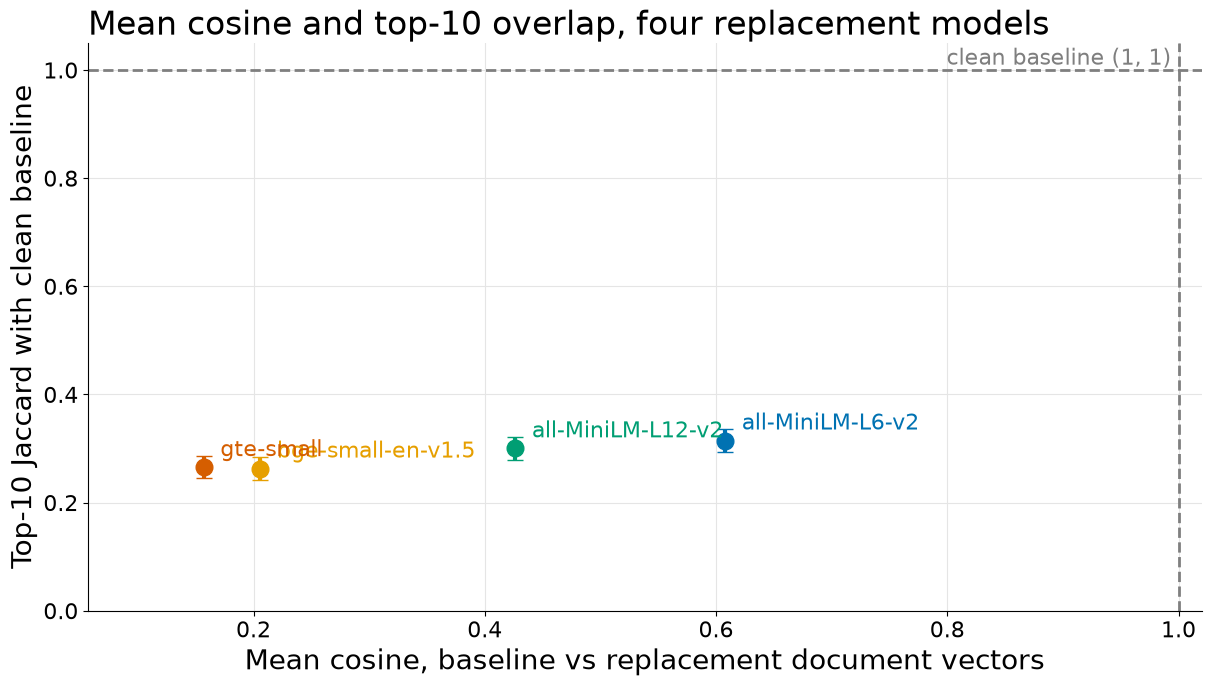

In [15]:
fig, ax = new_figure()
for l in LABELS:
    x, y = DIFF.loc[l, 'mean cosine'], DIFF.loc[l, 'top-10 Jaccard']
    yerr = [[y - DIFF.loc[l, 'Jaccard CI low']], [DIFF.loc[l, 'Jaccard CI high'] - y]]
    ax.errorbar(x, y, yerr=yerr, fmt='o', color=COLOR[l], ms=12, capsize=6, lw=3)
    ax.annotate(NAME[l], (x, y), xytext=(12, 8), textcoords='offset points', color=COLOR[l], fontsize=16)
ax.axhline(1, color=BASELINE_GREY, ls='--', lw=2)
ax.axvline(1, color=BASELINE_GREY, ls='--', lw=2)
ax.text(1, 1, 'clean baseline (1, 1) ', color=BASELINE_GREY, fontsize=16, ha='right', va='bottom')
ax.set_xlim(DIFF['mean cosine'].min() - 0.1, 1.02)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Mean cosine, baseline vs replacement document vectors')
ax.set_ylabel('Top-10 Jaccard with clean baseline')
# TODO: replace with the finding after the run
ax.set_title('Mean cosine and top-10 overlap, four replacement models')
save(fig, 'fig1_model_difference')

## 3. F1 dose–response: nDCG@10 decrease vs severity

For each replacement model, severity 0.1–1.0 and seed 0–9, `PartialUpgrade.apply` replaces a severity fraction of the document vectors (one permutation per seed, so higher severities replace a superset of rows), and all 323 test queries are searched with the baseline query vectors. No windows are used here.

**Interval.** The query is the unit. For each query, its paired difference (clean baseline nDCG@10 − nDCG@10 under the condition) is averaged over the 10 seeds; `bootstrap_ci` (10,000 resamples) is applied to those 323 per-query paired differences, giving the mean and a 95% bootstrap confidence interval (percentile). The clean baseline does not depend on the seed, so each per-query value equals the clean baseline nDCG@10 minus the seed mean under the condition. Queries × seeds are not pooled as independent observations.

In [16]:
doc_ids = np.asarray(state.doc_ids)


def swapped_docs(modified):
    return set(doc_ids[(modified.doc_embeddings != state.doc_embeddings).any(axis=1)])


qrows, f1_diff = [], {}
for l in LABELS:
    for s in SEVERITIES:
        per_seed = []
        for seed in SEEDS:
            modified = INJ[l].apply(state, s, seed)
            ids, _, _ = retriever.search(modified, k=K, query_embeddings=state.query_embeddings)
            nd = per_query_ndcg(ids, state.query_ids, ds.qrels, K)
            per_seed.append(clean_ndcg - nd)
            swapped = swapped_docs(modified)
            for q, c, v in zip(state.query_ids, clean_ndcg, nd):
                qrows.append({'query_id': q, 'model_label': l, 'direction': 'F1', 'severity': s, 'seed': seed,
                              'clean_baseline_ndcg10': c, 'modified_ndcg10': v, 'n_relevant': len(REL[q]),
                              'n_relevant_swapped': sum(d in swapped for d in REL[q]), 'query_swapped': False})
        f1_diff[l, s] = np.mean(per_seed, axis=0)

DOSE_F1 = pd.DataFrame([{'label': l, 'severity': s, **dict(zip(['mean', 'low', 'high'], bootstrap_ci(d)))}
                        for (l, s), d in f1_diff.items()])
display(DOSE_F1.pivot_table(index='severity', columns='label', values='mean').round(3))

label,F1_partial_upgrade_all_minilm_l12_v2,F1_partial_upgrade_bge,F1_partial_upgrade_gte_small,F1_partial_upgrade_minilm
severity,,,,
0.1,0.012,0.013,0.013,0.009
0.2,0.024,0.026,0.026,0.017
0.3,0.038,0.041,0.041,0.025
0.4,0.052,0.057,0.057,0.033
0.5,0.069,0.077,0.077,0.043
0.6,0.087,0.101,0.101,0.052
0.7,0.108,0.127,0.127,0.059
0.8,0.125,0.157,0.158,0.061
0.9,0.140,0.196,0.200,0.060


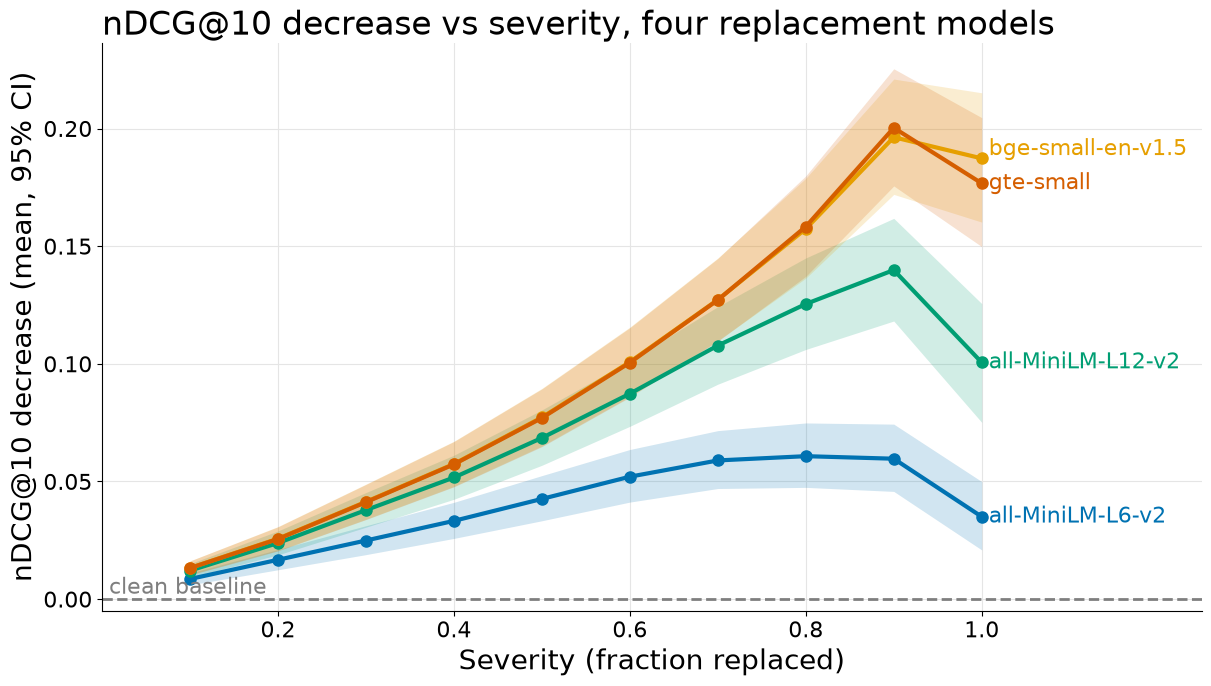

In [17]:
def dose_plot(ax, dose, ylabel, xmax=1.25):
    for l in LABELS:
        d = dose[dose.label == l].sort_values('severity')
        ax.fill_between(d.severity, d.low, d.high, color=COLOR[l], alpha=0.18, lw=0)
        ax.plot(d.severity, d['mean'], 'o-', color=COLOR[l])
    ax.set_xlim(0, xmax)
    ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xlabel('Severity (fraction replaced)')
    ax.set_ylabel(ylabel)
    baseline_line(ax, 0)


def ends_at_1(dose, column='mean'):
    return [(dose[(dose.label == l) & (dose.severity == 1.0)][column].item(), NAME[l], COLOR[l]) for l in LABELS]


fig, ax = new_figure()
dose_plot(ax, DOSE_F1, 'nDCG@10 decrease (mean, 95% CI)')
label_ends(ax, 1.0, ends_at_1(DOSE_F1))
# TODO: replace with the finding after the run
ax.set_title('nDCG@10 decrease vs severity, four replacement models')
save(fig, 'fig2_f1_ndcg_dose_response')

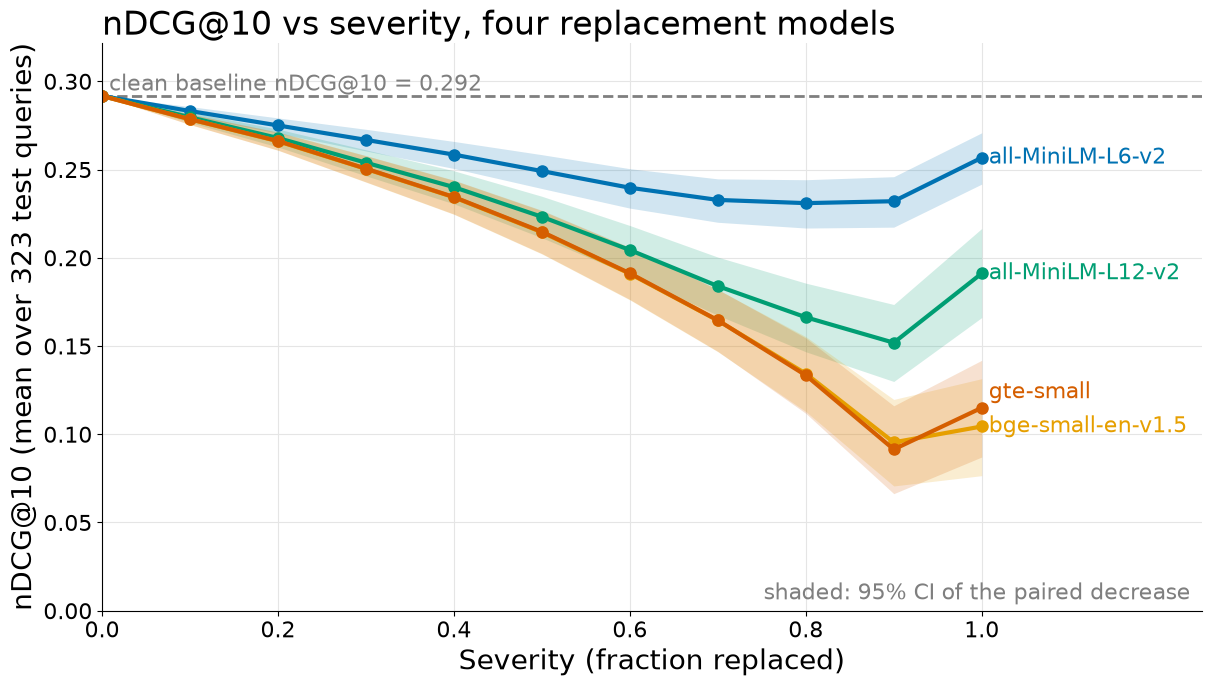

In [21]:
BASE = float(clean_ndcg.mean())  # clean baseline nDCG@10, 0.292

fig, ax = new_figure()
ax.set_xlim(0, 1.25)
ax.set_ylim(0, BASE + 0.03)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
for l in LABELS:
    d = DOSE_F1[DOSE_F1.label == l].sort_values('severity')
    x = np.r_[0.0, d.severity]                # severity 0 = clean baseline, no vectors replaced
    y = np.r_[BASE, BASE - d['mean']]
    lo = np.r_[BASE, BASE - d['high']]        # band: 95% CI of the paired decrease, shifted to the nDCG scale
    hi = np.r_[BASE, BASE - d['low']]
    ax.fill_between(x, lo, hi, color=COLOR[l], alpha=0.18, lw=0)
    ax.plot(x, y, 'o-', color=COLOR[l])
baseline_line(ax, BASE, f'clean baseline nDCG@10 = {BASE:.3f}')
label_ends(ax, 1.0, [(BASE - DOSE_F1[(DOSE_F1.label == l) & (DOSE_F1.severity == 1.0)]['mean'].item(), NAME[l], COLOR[l])
                     for l in LABELS])
ax.set_xlabel('Severity (fraction replaced)')
ax.set_ylabel('nDCG@10 (mean over 323 test queries)')
ax.text(0.99, 0.02, 'shaded: 95% CI of the paired decrease', transform=ax.transAxes, ha='right',
        fontsize=16, color=BASELINE_GREY)
# TODO: replace with the finding after the run
ax.set_title('nDCG@10 vs severity, four replacement models')
save(fig, 'fig2b_f1_ndcg_vs_severity')

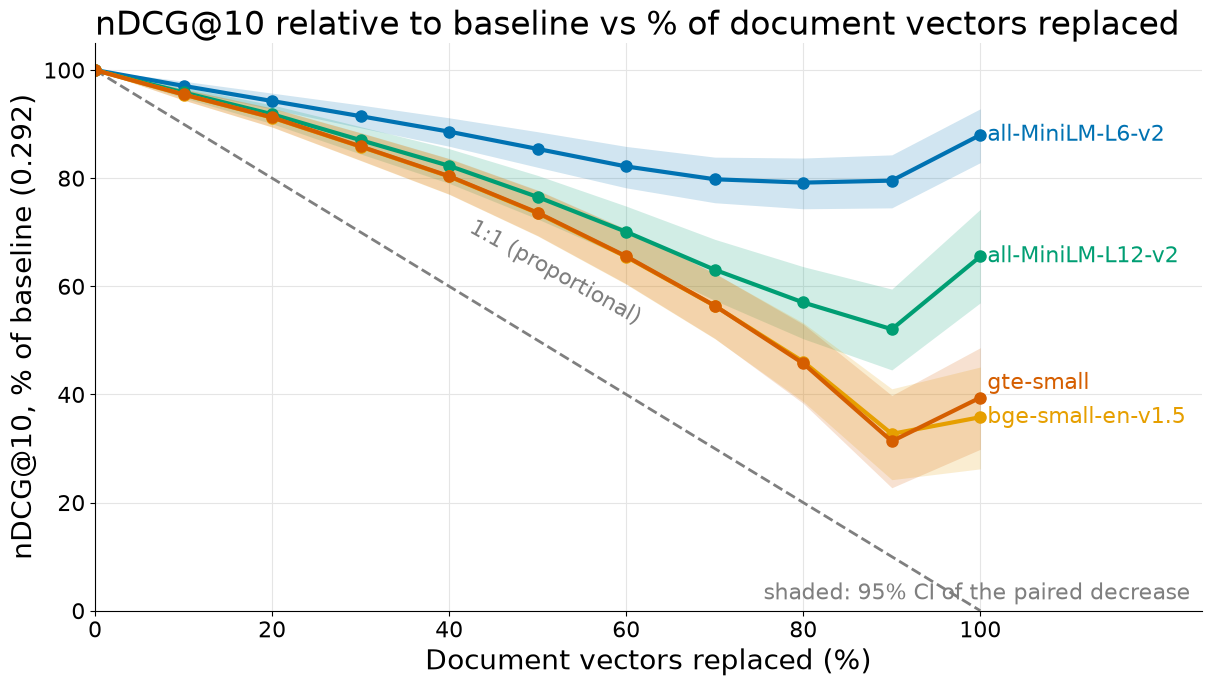

In [23]:
BASE = float(clean_ndcg.mean())  # clean baseline nDCG@10, 0.292

fig, ax = new_figure()
ax.set_xlim(0, 125)
ax.set_ylim(0, 105)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.plot([0, 100], [100, 0], color=BASELINE_GREY, ls='--', lw=2, zorder=1)
ax.text(52, 52, '1:1 (proportional)', color=BASELINE_GREY, fontsize=16, rotation=-29, ha='center', va='bottom')
for l in LABELS:
    d = DOSE_F1[DOSE_F1.label == l].sort_values('severity')
    x = np.r_[0.0, 100 * d.severity]
    y = np.r_[100.0, 100 * (BASE - d['mean']) / BASE]
    lo = np.r_[100.0, 100 * (BASE - d['high']) / BASE]   # band: 95% CI of the paired decrease, as % of baseline
    hi = np.r_[100.0, 100 * (BASE - d['low']) / BASE]
    ax.fill_between(x, lo, hi, color=COLOR[l], alpha=0.18, lw=0)
    ax.plot(x, y, 'o-', color=COLOR[l])
label_ends(ax, 100, [(100 * (BASE - DOSE_F1[(DOSE_F1.label == l) & (DOSE_F1.severity == 1.0)]['mean'].item()) / BASE,
                      NAME[l], COLOR[l]) for l in LABELS])
ax.set_xlabel('Document vectors replaced (%)')
ax.set_ylabel(f'nDCG@10, % of baseline ({BASE:.3f})')
ax.text(0.99, 0.02, 'shaded: 95% CI of the paired decrease', transform=ax.transAxes, ha='right',
        fontsize=16, color=BASELINE_GREY)
# TODO: replace with the finding after the run
ax.set_title('nDCG@10 relative to baseline vs % of document vectors replaced')
save(fig, 'fig2c_f1_ndcg_pct_vs_pct_replaced')

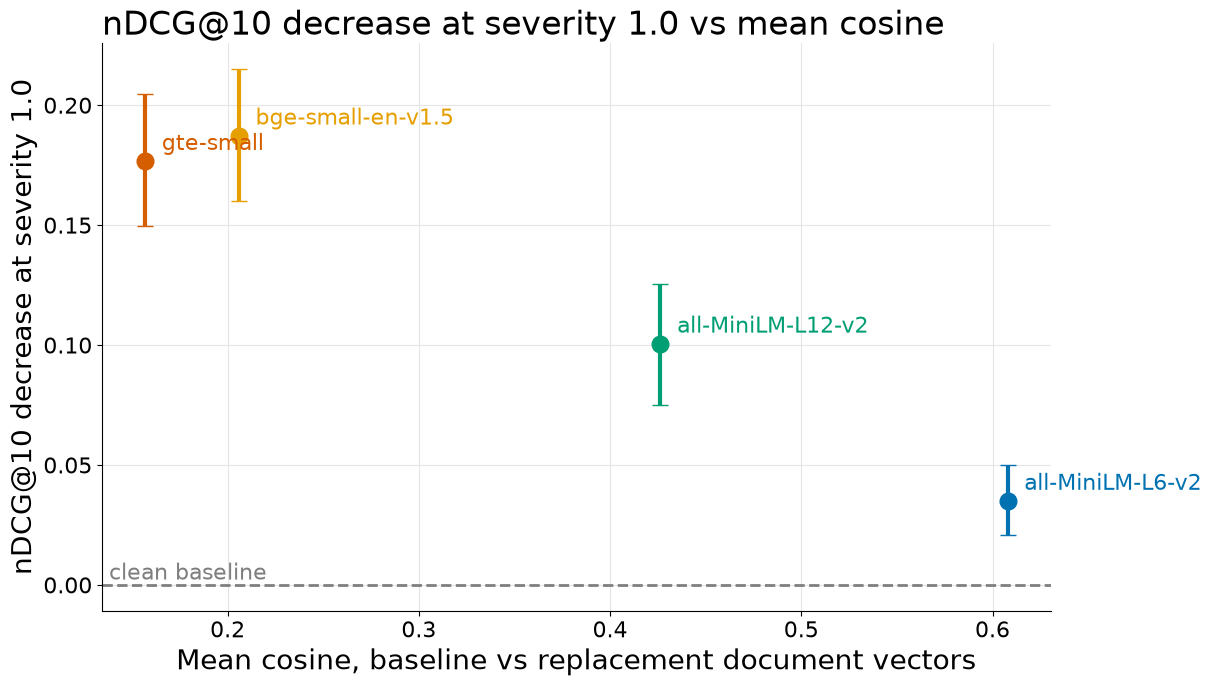

In [18]:
at1 = DOSE_F1[DOSE_F1.severity == 1.0].set_index('label')
fig, ax = new_figure()
for l in LABELS:
    x, y = MODELS[l]['mean_cosine'], at1.loc[l, 'mean']
    yerr = [[y - at1.loc[l, 'low']], [at1.loc[l, 'high'] - y]]
    ax.errorbar(x, y, yerr=yerr, fmt='o', color=COLOR[l], ms=12, capsize=6, lw=3)
    ax.annotate(NAME[l], (x, y), xytext=(12, 8), textcoords='offset points', color=COLOR[l], fontsize=16)
baseline_line(ax, 0)
ax.set_xlabel('Mean cosine, baseline vs replacement document vectors')
ax.set_ylabel('nDCG@10 decrease at severity 1.0')
# TODO: replace with the finding after the run
ax.set_title('nDCG@10 decrease at severity 1.0 vs mean cosine')
save(fig, 'fig3_f1_decrease_vs_mean_cosine')

## 4. F1 dose–response: detector statistics vs severity

Each detector is fitted once on the reference set (the clean baseline retrieval of the **324 validation queries**) and scores the retrieval of the **323 test queries** under each condition. The grey dashed line is the detector’s statistic for the clean baseline test set against the same reference set.

**Scale.** These statistics compare 324 validation vs 323 test queries, so they are not on the same scale as the runner’s statistics, which compare two 100-query windows (§6). PSI in particular has a smaller upward bias with larger samples.

**Band.** The line is the mean over the 10 seeds; the shaded band is the **range over 10 seeds** (minimum to maximum). It reflects variation in which document rows are replaced, not sampling error, so it is not a confidence interval.

In [19]:
ref_ids, ref_scores, ref_q = retriever.search(ref_state, k=K, query_embeddings=ref_state.query_embeddings)
reference = R.observe(ref_state, np.arange(len(ref_state.query_ids)), ref_ids, ref_scores, ref_q)
ALL_TEST = np.arange(len(state.query_ids))
FITTED = {}
for name in DETECTOR_NAMES:
    FITTED[name] = DETECTORS[name]()
    FITTED[name].attach(retriever)
    FITTED[name].fit(reference)

baseline_obs = R.observe(state, ALL_TEST, clean_ids, clean_scores, clean_q)
DET_BASELINE = {name: FITTED[name].score(baseline_obs) for name in DETECTOR_NAMES}
print('clean baseline test set vs reference set:', {k: round(v, 4) for k, v in DET_BASELINE.items()})

det_rows = []
for l in LABELS:
    for s in SEVERITIES:
        for seed in SEEDS:
            modified = R.read_only(INJ[l].apply(state, s, seed))
            ids, scores, q = retriever.search(modified, k=K, query_embeddings=state.query_embeddings)
            obs = R.observe(modified, ALL_TEST, ids, scores, q)
            for name in DETECTOR_NAMES:
                det_rows.append({'direction': 'F1', 'label': l, 'severity': s, 'seed': seed, 'detector': name,
                                 'score': FITTED[name].score(obs)})
DET = pd.DataFrame(det_rows)

clean baseline test set vs reference set: {'re_embed': 0.0, 'ks_top1': 0.0785, 'ks_mean10': 0.0629, 'ks_gap': 0.0793, 'psi_top1': 0.0935}


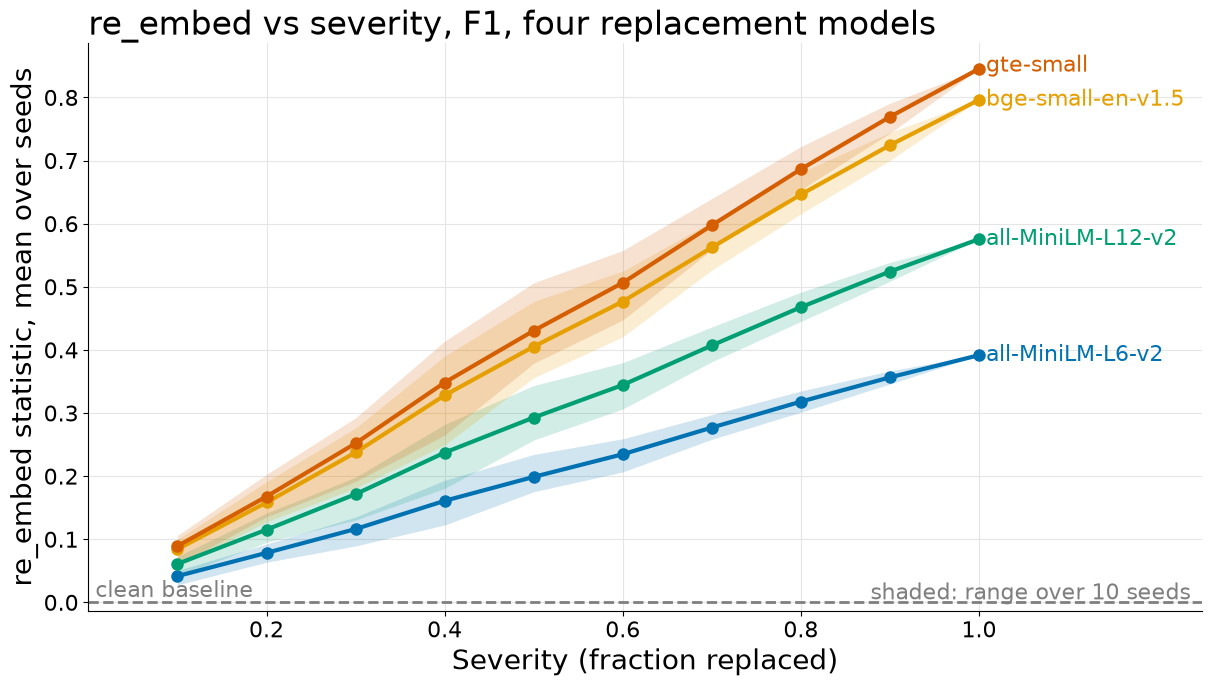

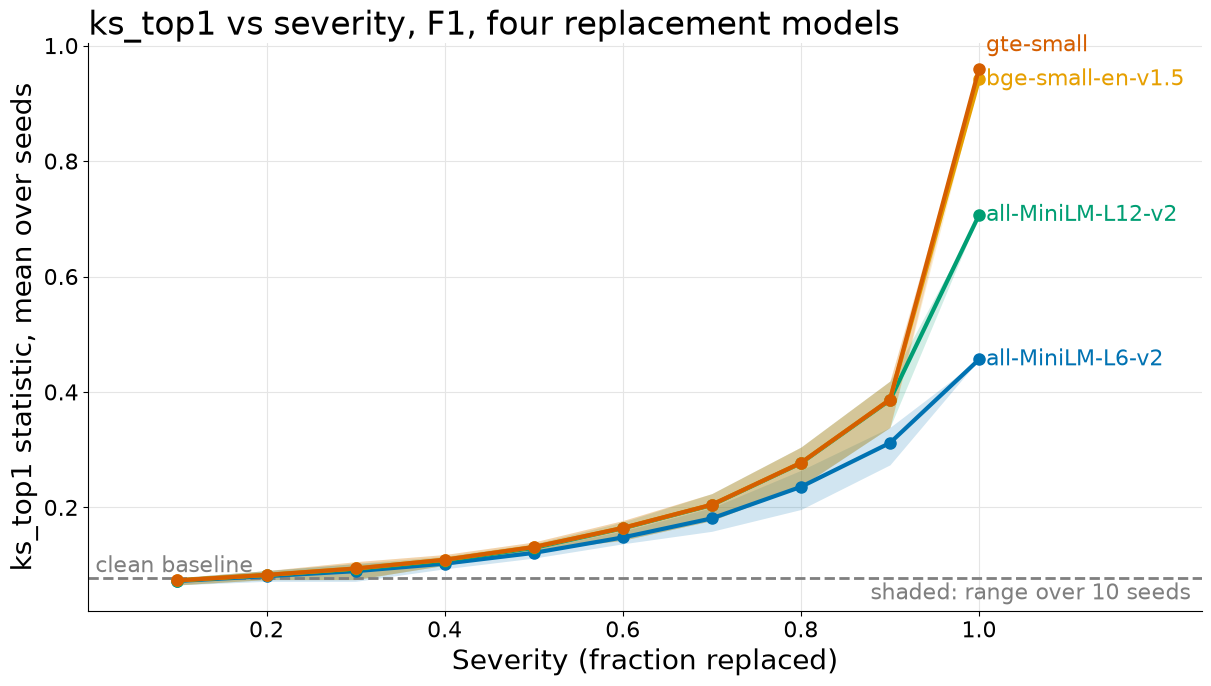

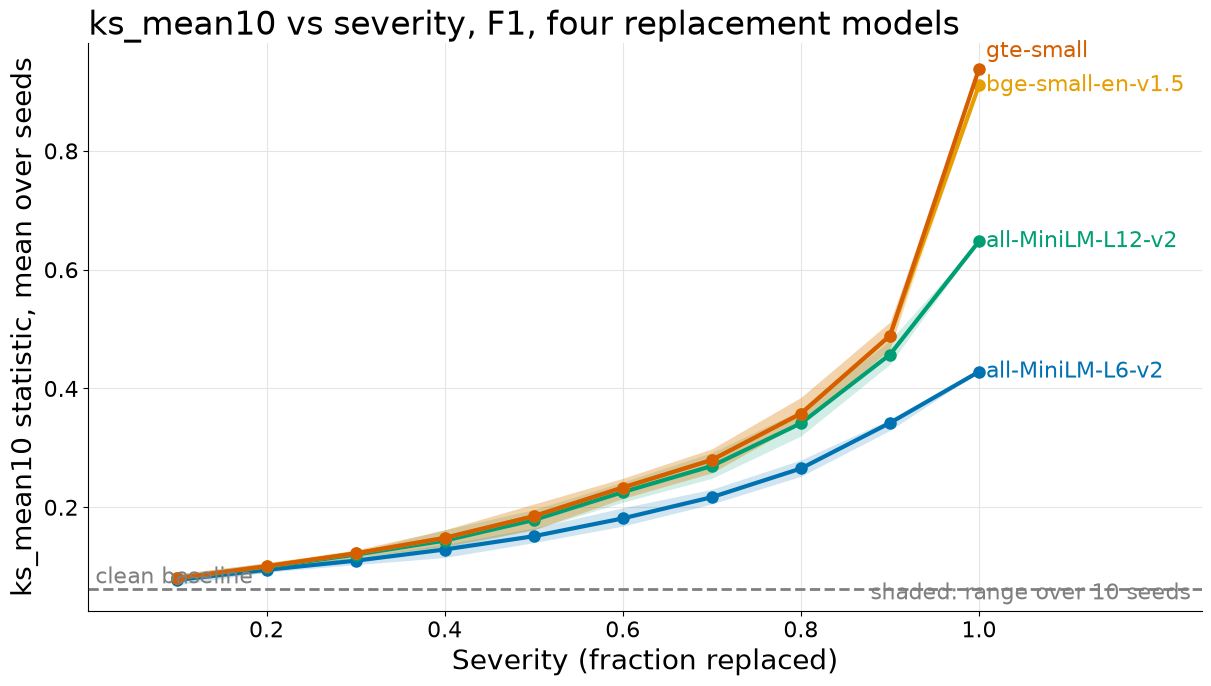

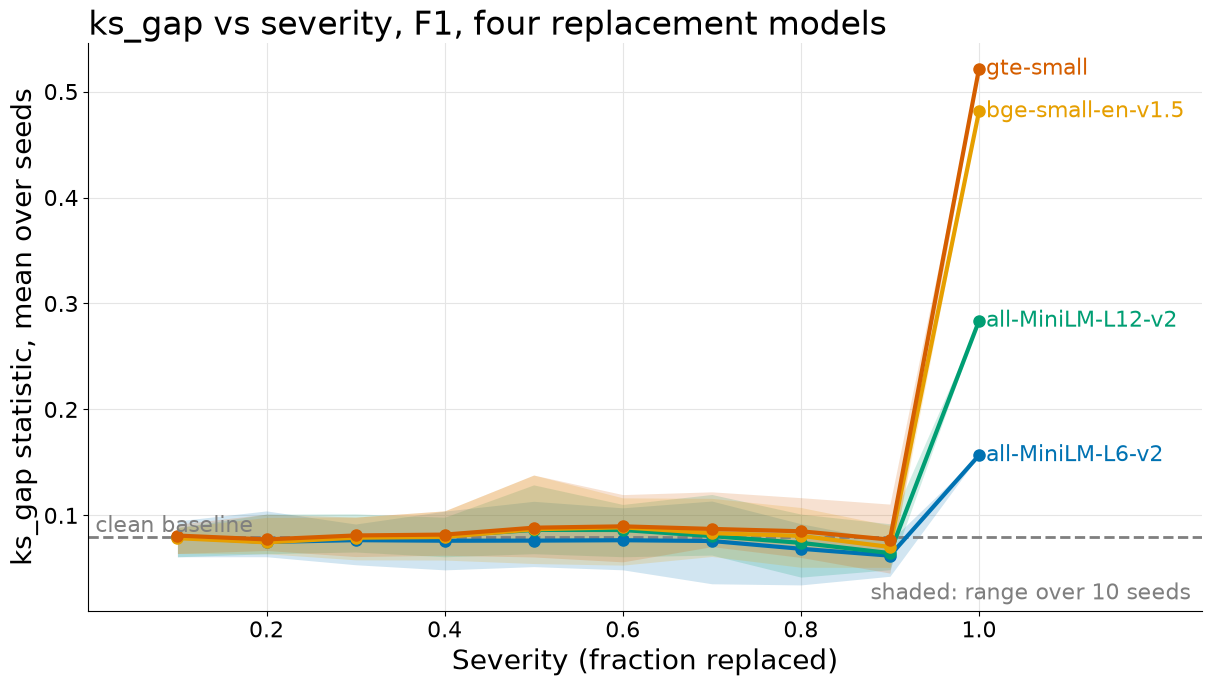

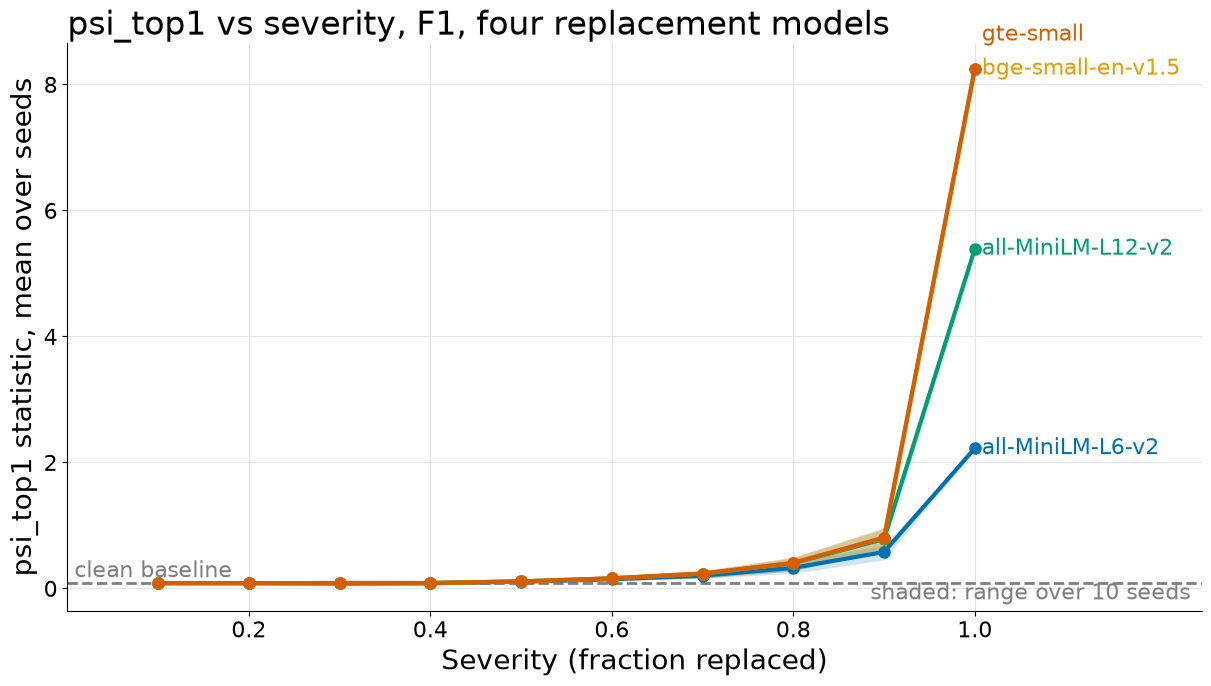

In [20]:
def detector_plots(direction, prefix):
    sub = DET[DET.direction == direction]
    for name in DETECTOR_NAMES:
        g = sub[sub.detector == name].groupby(['label', 'severity']).score.agg(['mean', 'min', 'max']).reset_index()
        fig, ax = new_figure()
        for l in LABELS:
            d = g[g.label == l].sort_values('severity')
            ax.fill_between(d.severity, d['min'], d['max'], color=COLOR[l], alpha=0.18, lw=0)
            ax.plot(d.severity, d['mean'], 'o-', color=COLOR[l])
        ax.set_xlim(0, 1.25)
        ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
        ax.set_xlabel('Severity (fraction replaced)')
        ax.set_ylabel(f'{name} statistic, mean over seeds')
        baseline_line(ax, DET_BASELINE[name])
        label_ends(ax, 1.0, [(g[(g.label == l) & (g.severity == 1.0)]['mean'].item(), NAME[l], COLOR[l]) for l in LABELS])
        ax.text(0.99, 0.02, 'shaded: range over 10 seeds', transform=ax.transAxes, ha='right', fontsize=16,
                color=BASELINE_GREY)
        # TODO: replace with the finding after the run
        ax.set_title(f'{name} vs severity, {direction}, four replacement models')
        save(fig, f'{prefix}_{name}')


detector_plots('F1', 'fig4_f1_detector')

## 5. Query-side mirror (analysis, not a benchmark condition)

The mirror of F1: all document vectors stay on the baseline model, and a severity fraction of the 323 test queries is embedded with the replacement model. The queries are chosen by one permutation per seed (`numpy.random.default_rng(seed).permutation(323)`, cut at the severity), so higher severities replace a superset of queries, the same nested rule F1 uses for document rows. bge queries use its instruction, as in §2. This is computed with existing functions only (`Retriever.embed_queries`, `Retriever.search` with `query_embeddings`, `per_query_ndcg`, `bootstrap_ci`, the detectors’ `fit` / `score`) and is **not** a benchmark condition: it is not in the runner results.

`re_embed` is included. It compares stored document vectors with fresh baseline-model vectors, and no document vector changes in the mirror, so its statistic is expected to be 0; it is measured here, not assumed.

The interval method of §3 (per-query paired differences averaged over seeds, then `bootstrap_ci` over queries) and the detector set-up of §4 apply: the detector statistics compare 324 validation vs 323 test queries and are not on the scale of the runner’s 100-query windows (§6); the band is the range over 10 seeds.

In [ ]:
mirror_diff = {}
NQ = len(state.query_ids)
for l in LABELS:
    for s in SEVERITIES:
        per_seed = []
        for seed in SEEDS:
            sel = np.random.default_rng(seed).permutation(NQ)[: round(s * NQ)]
            q = state.query_embeddings.copy()
            q[sel] = ALT_Q[l][sel]
            ids, scores, q = retriever.search(state, k=K, query_embeddings=q)
            nd = per_query_ndcg(ids, state.query_ids, ds.qrels, K)
            per_seed.append(clean_ndcg - nd)
            chosen = np.zeros(NQ, dtype=bool)
            chosen[sel] = True
            for qid, c, v, w in zip(state.query_ids, clean_ndcg, nd, chosen):
                qrows.append({'query_id': qid, 'model_label': l, 'direction': 'mirror', 'severity': s, 'seed': seed,
                              'clean_baseline_ndcg10': c, 'modified_ndcg10': v, 'n_relevant': len(REL[qid]),
                              'n_relevant_swapped': None, 'query_swapped': bool(w)})
            obs = R.observe(state, ALL_TEST, ids, scores, q)
            for name in DETECTOR_NAMES:
                det_rows.append({'direction': 'mirror', 'label': l, 'severity': s, 'seed': seed, 'detector': name,
                                 'score': FITTED[name].score(obs)})
        mirror_diff[l, s] = np.mean(per_seed, axis=0)

DET = pd.DataFrame(det_rows)
DOSE_MIRROR = pd.DataFrame([{'label': l, 'severity': s, **dict(zip(['mean', 'low', 'high'], bootstrap_ci(d)))}
                            for (l, s), d in mirror_diff.items()])
display(DOSE_MIRROR.pivot_table(index='severity', columns='label', values='mean').round(3))
print('re_embed statistic in the mirror, maximum over all conditions:',
      DET[(DET.direction == 'mirror') & (DET.detector == 're_embed')].score.max())

In [ ]:
fig, axes = new_figure(ncols=2, sharey=True)
for ax, dose, title in zip(axes, [DOSE_F1, DOSE_MIRROR], ['F1: document vectors replaced', 'Mirror: query vectors replaced']):
    dose_plot(ax, dose, 'nDCG@10 decrease (mean, 95% CI)', xmax=1.5)
    ax.set_title(title, fontsize=20)
for ax, dose in zip(axes, [DOSE_F1, DOSE_MIRROR]):
    label_ends(ax, 1.0, ends_at_1(dose))
axes[1].set_ylabel('')
# TODO: replace with the finding after the run
fig.suptitle('nDCG@10 decrease vs severity, F1 and query-side mirror', fontsize=24, x=0.02, ha='left')
save(fig, 'fig5_f1_vs_mirror_ndcg')

detector_plots('mirror', 'fig5b_mirror_detector')

### Per-query table

`results/analysis_f1_queries.parquet` has one row per test query × replacement model × direction × severity × seed: `query_id`, `model_label`, `direction` (`F1` or `mirror`), `severity`, `seed`, `clean_baseline_ndcg10`, `modified_ndcg10`, `n_relevant` (qrels relevance > 0), `n_relevant_swapped` (relevant documents whose vectors F1 replaced; null in the mirror, where no document vector is replaced) and `query_swapped` (whether the query was embedded with the replacement model; always false for F1). It is not analysed in this notebook.

This file is a deliberate exception to the “add new columns to `ResultRow`, not side CSVs” rule in CLAUDE.md: it has a different grain (one row per query, not one row per window and detector).

In [ ]:
QUERIES = pd.DataFrame(qrows).astype({'n_relevant_swapped': 'Int64'})
QUERIES.to_parquet(QUERIES_PATH, index=False)
print(f'wrote {len(QUERIES)} rows to {QUERIES_PATH}')
QUERIES.groupby(['direction', 'model_label']).size().to_frame('rows')

## 6. AUROC per detector (benchmark run from §1c)

`compute_auroc` and `bootstrap_auroc_ci` on the runner results. Positives are the windows of one F1 condition labelled harmful (`min_drop` = 0); negatives are the clean baseline windows. Windows of that condition that are not labelled harmful are excluded (`detector_scoring.py:70-77`). The 95% confidence interval resamples whole seeds (10 blocks, 2,000 resamples), so it reflects variation between independent runs, not a population of queries.

**Pooled:** all severities of a condition together. **Per severity:** the results table is filtered to the clean baseline windows plus one severity before the same functions are called. Where a severity has no window labelled harmful, AUROC is undefined and left out (listed below the table). The grey dashed line is AUROC = 0.5 (no discrimination); AUROC has no clean-baseline value.

In [ ]:
if runs is None:
    raise RuntimeError(f'{RUNNER_PATH} not found: start the benchmark run from §1c, then rerun §1c')
auc_rows, undefined = [], []
for l in LABELS:
    for name in DETECTOR_NAMES:
        a, lo, hi = bootstrap_auroc_ci(runs, name, l)
        assert a == compute_auroc(runs, name, l)
        auc_rows.append({'label': l, 'detector': name, 'severity': 'pooled', 'auroc': a, 'low': lo, 'high': hi})
        for s in SEVERITIES:
            sub = runs[(runs.failure == 'clean') | ((runs.failure == l) & (runs.severity == s))]
            try:
                a, lo, hi = bootstrap_auroc_ci(sub, name, l)
            except ValueError as e:
                undefined.append((l, name, s, str(e)))
                continue
            auc_rows.append({'label': l, 'detector': name, 'severity': s, 'auroc': a, 'low': lo, 'high': hi})
AUC = pd.DataFrame(auc_rows)
display(AUC[AUC.severity == 'pooled'].pivot_table(index='detector', columns='label', values='auroc').round(3))
if undefined:
    display(pd.DataFrame(undefined, columns=['label', 'detector', 'severity', 'reason']))

In [ ]:
per_sev = AUC[AUC.severity != 'pooled'].astype({'severity': float})
for name in DETECTOR_NAMES:
    fig, ax = new_figure()
    ends = []
    for l in LABELS:
        d = per_sev[(per_sev.detector == name) & (per_sev.label == l)].sort_values('severity')
        ax.fill_between(d.severity, d.low, d.high, color=COLOR[l], alpha=0.18, lw=0)
        ax.plot(d.severity, d.auroc, 'o-', color=COLOR[l])
        if len(d):
            ends.append((d.auroc.iloc[-1], NAME[l], COLOR[l]))
    ax.set_xlim(0, 1.25)
    ax.set_ylim(0.3, 1.05)
    ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xlabel('Severity (fraction replaced)')
    ax.set_ylabel('AUROC (95% CI over seeds)')
    baseline_line(ax, 0.5, 'AUROC 0.5 (no discrimination)')
    label_ends(ax, 1.0, ends)
    # TODO: replace with the finding after the run
    ax.set_title(f'AUROC of {name} vs severity, four replacement models')
    save(fig, f'fig6_auroc_{name}')

## 7. Share of windows labelled harmful at three thresholds

The harmful label recomputed from the runner’s `p_value` and `ndcg_drop` columns: p < α = 0.05 and mean nDCG@10 decrease ≥ `min_drop`, for `min_drop` = 0, 0.02 and 0.06. The value 0.06 is the smallest mean nDCG@10 decrease detected in 80% of 100-query windows at α = 0.05 (README, window-size analysis, `experiments/baseline/window_size.py`). Each point is the share of the 200 windows (20 per seed × 10 seeds) at that severity. The grey dashed line is the share of clean baseline windows labelled harmful.

In [ ]:
if runs is None:
    raise RuntimeError(f'{RUNNER_PATH} not found: start the benchmark run from §1c, then rerun §1c')
WIN = runs.drop_duplicates(['failure', 'severity', 'seed', 'trial'])
share_rows = []
for min_drop in MIN_DROPS:
    labelled = (WIN.p_value < ALPHA) & (WIN.ndcg_drop >= min_drop)
    for (f, s), v in labelled.groupby([WIN.failure, WIN.severity]).mean().items():
        share_rows.append({'min_drop': min_drop, 'label': f, 'severity': s, 'share': 100 * v})
SHARE = pd.DataFrame(share_rows)
display(SHARE[SHARE.label != 'clean'].pivot_table(index='severity', columns=['min_drop', 'label'], values='share').round(0))

for min_drop in MIN_DROPS:
    fig, ax = new_figure()
    sub = SHARE[SHARE.min_drop == min_drop]
    for l in LABELS:
        d = sub[sub.label == l].sort_values('severity')
        ax.plot(d.severity, d.share, 'o-', color=COLOR[l])
    ax.set_xlim(0, 1.25)
    ax.set_ylim(-3, 105)
    ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xlabel('Severity (fraction replaced)')
    ax.set_ylabel('% of windows labelled harmful')
    baseline_line(ax, sub[sub.label == 'clean'].share.item())
    label_ends(ax, 1.0, [(sub[(sub.label == l) & (sub.severity == 1.0)].share.item(), NAME[l], COLOR[l]) for l in LABELS])
    # TODO: replace with the finding after the run
    ax.set_title(f'% of windows labelled harmful vs severity, min_drop = {min_drop:g}')
    save(fig, f'fig7_harmful_share_min_drop_{min_drop:g}')

## 8. Median computation time per detector check

Medians of the runner’s `cost_s` column over every check of the benchmark run (8,200 windows per detector): the time to score one 100-query window after fitting. Notebook timings are not used. Printed with the machine record (§0) and, from `/tmp/analysis_f1_load.log`, whether the run overlapped other CPU-intensive processes: a one-minute sample counts as overlapping when a process other than the runner used ≥ 50% CPU. Log scale.

In [ ]:
if runs is None:
    raise RuntimeError(f'{RUNNER_PATH} not found: start the benchmark run from §1c, then rerun §1c')


def overlap_record(path=LOAD_LOG, cpu_threshold=50.0):
    if not path.exists():
        return None
    runner_pid, samples, current = None, [], None
    for line in path.read_text().splitlines():
        parts = line.split(None, 2)
        if parts[:1] == ['runner_pid']:
            runner_pid = parts[1]
        elif parts[:1] == ['sample']:
            current = []
            samples.append(current)
        elif current is not None and len(parts) == 3 and parts[1].isdigit() and parts[1] != runner_pid:
            if float(parts[0]) >= cpu_threshold:
                current.append(parts[2].strip().rsplit('/', 1)[-1])
    overlapping = [s for s in samples if s]
    return {'one_minute_samples': len(samples), 'samples_with_another_process_at_or_above_50pct_cpu': len(overlapping),
            'other_processes': sorted({p for s in overlapping for p in s})}


cost = runs.groupby('detector').cost_s.agg(['median', 'count']).sort_values('median')
cost['median_ms'] = cost['median'] * 1000
display(cost[['median_ms', 'count']].round(3))
print('machine:', json.dumps(MACHINE, indent=1))
OVERLAP = overlap_record()
if OVERLAP is None:
    print(f'no load log at {LOAD_LOG}: whether the run overlapped other CPU-intensive processes is not recorded')
else:
    n, k_ = OVERLAP['one_minute_samples'], OVERLAP['samples_with_another_process_at_or_above_50pct_cpu']
    verdict, others = ('overlapped' if k_ else 'did not overlap'), OVERLAP['other_processes']
    print(f'the benchmark run {verdict} other CPU-intensive processes: {k_} of {n} one-minute samples; '
          f'processes: {others}')

fig, ax = new_figure()
ax.barh(cost.index, cost.median_ms, color=BASELINE_GREY)
for y, v in enumerate(cost.median_ms):
    ax.text(v * 1.15, y, f'{v / 1000:.1f} s' if v >= 1000 else f'{v:.2f} ms', va='center', fontsize=16)
ax.set_xscale('log')
ax.set_xlim(cost.median_ms.min() / 3, cost.median_ms.max() * 10)
ax.set_xlabel('Median time per check (ms, log scale)')
ax.grid(axis='y', visible=False)
# TODO: replace with the finding after the run
ax.set_title('Median time per detector check, one 100-query window')
save(fig, 'fig8_cost_per_check')